In [1]:
# ============================================================
# WEEK 11: CROSS-DATASET GENERALIZATION
# ============================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Project paths
ROOT = Path.cwd().parent

RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
DATASET_DIR = ROOT / "dataset"
DATASETS_DIR = ROOT / "datasets"

CHECKPOINT_PATH = MODELS_DIR / "week4_resnet50.pth"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Week 11: Cross-Dataset Generalization")
print("Project Root:", ROOT)
print("Device:", device)

print("CUDA Available:", torch.cuda.is_available())
print("ResNet50 Checkpoint:", CHECKPOINT_PATH.exists())

print("\nDataset folders:")

for folder in [DATASET_DIR, DATASETS_DIR]:
    print(folder.name, ":", folder.exists())

Week 11: Cross-Dataset Generalization
Project Root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda
CUDA Available: True
ResNet50 Checkpoint: True

Dataset folders:
dataset : False
datasets : True


In [2]:
# ============================================================
# CELL 2: CHECK AVAILABLE DATASETS
# ============================================================

print("DATASETS FOLDER CONTENTS\n")

for item in DATASETS_DIR.iterdir():

    if item.is_dir():
        print("[FOLDER]", item.name)

        sub_items = list(item.iterdir())

        for sub_item in sub_items[:10]:
            print("   ", sub_item.name)

        if len(sub_items) > 10:
            print("    ...")

    else:
        print("[FILE]", item.name)

print("\nChecking common external dataset folders...")

for folder in DATASETS_DIR.rglob("*"):

    if folder.is_dir() and any(
        word in folder.name.lower()
        for word in ["ff++", "faceforensics", "dfdc", "celeb"]
    ):
        print("Found:", folder)

DATASETS FOLDER CONTENTS

[FOLDER] Celeb-DF-v2
    Celeb-real
    Celeb-synthesis
    List_of_testing_videos.txt
    YouTube-real

Checking common external dataset folders...
Found: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2
Found: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2\Celeb-real
Found: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2\Celeb-synthesis


In [3]:
# ============================================================
# CELL 3: VIDEO-LEVEL DATA SPLIT VERIFICATION
# ============================================================

metadata_path = RESULTS_DIR / "final_face_metadata.csv"

metadata_df = pd.read_csv(metadata_path)

# Keep valid face images
metadata_df = metadata_df[
    metadata_df["file_exists"].astype(str).str.lower().isin(
        ["true", "1"]
    )
].copy()

# Separate datasets
train_df = metadata_df[metadata_df["split"] == "train"].copy()
val_df = metadata_df[metadata_df["split"] == "val"].copy()
test_df = metadata_df[metadata_df["split"] == "test"].copy()

# Get unique video IDs
train_videos = set(train_df["video_id"].dropna().unique())
val_videos = set(val_df["video_id"].dropna().unique())
test_videos = set(test_df["video_id"].dropna().unique())

# Check video overlap
train_val_overlap = train_videos.intersection(val_videos)
train_test_overlap = train_videos.intersection(test_videos)
val_test_overlap = val_videos.intersection(test_videos)

print("VIDEO-LEVEL SPLIT ANALYSIS")
print("=" * 50)

print("Train Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Test Images:", len(test_df))

print("\nUnique Videos:")
print("Train Videos:", len(train_videos))
print("Validation Videos:", len(val_videos))
print("Test Videos:", len(test_videos))

print("\nVIDEO OVERLAP CHECK")
print("Train-Val Overlap:", len(train_val_overlap))
print("Train-Test Overlap:", len(train_test_overlap))
print("Val-Test Overlap:", len(val_test_overlap))

if not train_val_overlap and not train_test_overlap and not val_test_overlap:
    print("\nSUCCESS: No video overlap detected!")
else:
    print("\nWARNING: Video overlap detected!")

VIDEO-LEVEL SPLIT ANALYSIS
Train Images: 39450
Validation Images: 9870
Test Images: 12321

Unique Videos:
Train Videos: 3945
Validation Videos: 987
Test Videos: 1233

VIDEO OVERLAP CHECK
Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0

SUCCESS: No video overlap detected!


In [4]:
# ============================================================
# CELL 4: UNSEEN TEST VIDEO DISTRIBUTION
# ============================================================

test_video_df = (
    test_df.groupby("video_id")
    .agg(
        true_label=("label", "first"),
        face_count=("face_path", "count")
    )
    .reset_index()
)

test_video_df["class_name"] = test_video_df["true_label"].map({
    0: "Real",
    1: "Deepfake"
})

print("UNSEEN TEST VIDEO DISTRIBUTION")
print("=" * 45)

print("\nVideo Class Distribution:")
print(test_video_df["class_name"].value_counts())

print("\nTotal Unique Test Videos:",
      test_video_df["video_id"].nunique())

print("\nFace Count Statistics:")
print(test_video_df["face_count"].describe())

print("\nSample Video Records:")
print(test_video_df.head(10).to_string(index=False))

# Save results
test_video_df.to_csv(
    RESULTS_DIR / "week11_unseen_test_video_distribution.csv",
    index=False
)

print("\nUnseen video distribution saved successfully!")

UNSEEN TEST VIDEO DISTRIBUTION

Video Class Distribution:
class_name
Deepfake    1061
Real         172
Name: count, dtype: int64

Total Unique Test Videos: 1233

Face Count Statistics:
count    1233.000000
mean        9.992701
std         0.256307
min         1.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        10.000000
Name: face_count, dtype: float64

Sample Video Records:
video_id  true_label  face_count class_name
   00000           0          10       Real
   00001           0          10       Real
   00002           0          10       Real
   00003           0          10       Real
   00004           0          10       Real
   00011           0          10       Real
   00012           0          10       Real
   00015           0          10       Real
   00030           0          10       Real
   00038           0          10       Real

Unseen video distribution saved successfully!


In [5]:
# ============================================================
# CELL 5: UNSEEN VIDEO PREDICTION ANALYSIS
# ============================================================

prediction_path = RESULTS_DIR / "week9_video_level_predictions.csv"

video_predictions = pd.read_csv(prediction_path)

print("Loaded Predictions:", len(video_predictions))
print("\nAvailable Columns:")
print(video_predictions.columns.tolist())

# Verify required columns
required_columns = [
    "video_id",
    "true_label",
    "predicted_label",
    "probability_fake"
]

missing_columns = [
    col for col in required_columns
    if col not in video_predictions.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Calculate correct and incorrect predictions
video_predictions["correct"] = (
    video_predictions["true_label"] ==
    video_predictions["predicted_label"]
)

correct_count = video_predictions["correct"].sum()
incorrect_count = (~video_predictions["correct"]).sum()

print("\nUNSEEN VIDEO PREDICTION SUMMARY")
print("=" * 45)

print("Total Videos:", len(video_predictions))
print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", incorrect_count)

print(
    "Prediction Accuracy:",
    round(correct_count / len(video_predictions), 4)
)

print("\nPrediction Distribution:")
print(
    video_predictions["predicted_label"].value_counts()
)

print("\nCorrect vs Incorrect:")
print(video_predictions["correct"].value_counts())

# Save analysis
video_predictions.to_csv(
    RESULTS_DIR / "week11_unseen_video_predictions.csv",
    index=False
)

print("\nUnseen video predictions saved successfully!")

Loaded Predictions: 1233

Available Columns:
['video_path', 'video_id', 'true_label', 'probability_fake', 'face_count', 'predicted_label']

UNSEEN VIDEO PREDICTION SUMMARY
Total Videos: 1233
Correct Predictions: 1121
Incorrect Predictions: 112
Prediction Accuracy: 0.9092

Prediction Distribution:
predicted_label
1    1151
0      82
Name: count, dtype: int64

Correct vs Incorrect:
correct
True     1121
False     112
Name: count, dtype: int64

Unseen video predictions saved successfully!


CONFUSION MATRIX
[[  71  101]
 [  11 1050]]

CLASSIFICATION REPORT
              precision  recall  f1-score    support
Real             0.8659  0.4128    0.5591   172.0000
Deepfake         0.9123  0.9896    0.9494  1061.0000
accuracy         0.9092  0.9092    0.9092     0.9092
macro avg        0.8891  0.7012    0.7542  1233.0000
weighted avg     0.9058  0.9092    0.8949  1233.0000


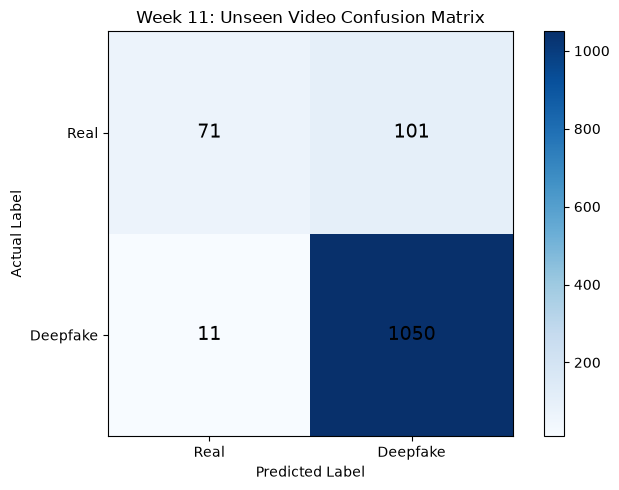


Confusion matrix and classification report saved!


In [7]:
# ============================================================
# CELL 6: CONFUSION MATRIX AND CLASSIFICATION REPORT
# ============================================================

import matplotlib.pyplot as plt

y_true = video_predictions["true_label"]
y_pred = video_predictions["predicted_label"]

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("CONFUSION MATRIX")
print("=" * 40)
print(cm)

# Generate classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=["Real", "Deepfake"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASSIFICATION REPORT")
print("=" * 40)
print(report_df.round(4))

# Plot confusion matrix using Matplotlib
plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Week 11: Unseen Video Confusion Matrix")
plt.colorbar()

classes = ["Real", "Deepfake"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Add values inside matrix
for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "week11_unseen_video_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save classification report
report_df.to_csv(
    RESULTS_DIR / "week11_unseen_video_classification_report.csv"
)

print("\nConfusion matrix and classification report saved!")

In [8]:
# ============================================================
# CELL 7: WEEK 11 FINAL GENERALIZATION SUMMARY
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_true = video_predictions["true_label"]
y_pred = video_predictions["predicted_label"]
y_prob = video_predictions["probability_fake"]

# Calculate final metrics
final_metrics = {
    "Evaluation": "Unseen Video Generalization",
    "Total Videos": len(video_predictions),
    "Correct Predictions": int((y_true == y_pred).sum()),
    "Incorrect Predictions": int((y_true != y_pred).sum()),
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-Score": f1_score(y_true, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, y_prob)
}

summary_df = pd.DataFrame([final_metrics])

print("WEEK 11 FINAL SUMMARY")
print("=" * 50)
print(summary_df.to_string(index=False))

summary_df.to_csv(
    RESULTS_DIR / "week11_final_generalization_summary.csv",
    index=False
)

print("\nWeek 11 summary saved successfully!")

WEEK 11 FINAL SUMMARY
                 Evaluation  Total Videos  Correct Predictions  Incorrect Predictions  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Unseen Video Generalization          1233                 1121                    112  0.909165    0.91225 0.989632  0.949367 0.849382

Week 11 summary saved successfully!
